# Tutorial 2: Integrative and generative analysis of mouse brain data (spatial epigenome-transcriptome data)

In this tutorial, we demonstrate how to apply MultiGlue for integrative and generative analysis of spatial-epigenome-transcriptome data. As an example, we analyze a mouse brain dataset. This dataset is a postnatal day (P)22 mouse brain coronal section with approximate 10,000 cells, profiled simultaneously by transcriptomic and chromatin accessibility assays. Following our previous study SpatialGlue (Long et al., 2024), we annotated the brain anatomical regions based on the Allen Brain Atlas.

Before running the pipeline, we can download the input data via https://drive.google.com/drive/folders/1ojWOujySQpkAQXwxIiwtblwx-o-LjY-_?usp=share_link.

# Loading package

In [1]:
import os
import torch
import pandas as pd
import scanpy as sc
import pickle
import numpy as np

In [2]:
import MultiGlue

In [3]:
# Environment configuration. MultiGlue pacakge can be implemented with either CPU or GPU. GPU acceleration is highly recommend for imporoved efficiency.
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# The location of R, which is required for the 'mclust' clustering algorithm. Please replace the path below with local R installation path
os.environ['R_HOME'] = '/home/andy/miniconda3/envs/MultiGlue/lib/R'

# Loading data

In [4]:
# read data
file_fold = '/home/andy/miniconda3/work/MultiGlue/data/data_202060129/p22_mouse_brain/' #please replace 'file_fold' with the download path

with open(file_fold + 'adj_full_17.pkl','rb') as f:
    adj_graph = pickle.load(f)    
    
adata_omics1 = sc.read_h5ad(file_fold + 'rna.h5ad')
adata_omics2 = sc.read_h5ad(file_fold + 'atac.h5ad')

adata_omics1.var_names_make_unique()
adata_omics2.var_names_make_unique()

print('RNA:', adata_omics1)
print('ATAC:', adata_omics2)

RNA: AnnData object with n_obs × n_vars = 9215 × 22914
    obs: 'RNA_clusters', 'ATAC_clusters', 'tissue'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    obsm: 'spatial'
    layers: 'counts'
ATAC: AnnData object with n_obs × n_vars = 9215 × 121068
    obs: 'RNA_clusters', 'ATAC_clusters', 'tissue'
    var: 'chrom', 'chromStart', 'chromEnd', 'highly_variable'
    obsm: 'spatial'


In [5]:
from MultiGlue.preprocess import fix_seed
# Setting random seed
random_seed = 2022
fix_seed(random_seed)

# Specifying input data type
data_type = 'Spatial-epigenome-transcriptome'

In [6]:
from MultiGlue.preprocess import neighbor_context_features, construct_neighbor_graph, permutation, clr_normalize_each_cell, lsi, pca

In [7]:
# Construct spatial graph
adata_omics1, adata_omics2 = construct_neighbor_graph(adata_omics1, adata_omics2)

In [8]:
# RNA
#sc.pp.filter_genes(adata_omics1, min_cells=10)
#sc.pp.filter_cells(adata_omics1, min_genes=200)

#sc.pp.highly_variable_genes(adata_omics1, flavor="seurat_v3", n_top_genes=3000)
sc.pp.normalize_total(adata_omics1, target_sum=1e4)
sc.pp.log1p(adata_omics1)
sc.pp.scale(adata_omics1)
adata_omics1 =  adata_omics1[:, adata_omics1.var['highly_variable']]

/home/andy/miniconda3/envs/MultiGlue/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [9]:
adata_omics1.obsm['feat'] = pca(adata_omics1, n_comps=50)
adata_omics1.obsm['feat_a'] = permutation(adata_omics1.obsm['feat'].copy())

/tmp/ipykernel_17852/3504079402.py:1: ImplicitModificationWarning: Setting element `.obsm['feat']` of view, initializing view as actual.
  adata_omics1.obsm['feat'] = pca(adata_omics1, n_comps=50)


In [10]:
# ATAC
adata_omics2 = adata_omics2[adata_omics1.obs_names].copy() # .obsm['X_lsi'] represents the dimension reduced feature
if 'X_lsi' not in adata_omics2.obsm.keys():
    #sc.pp.highly_variable_genes(adata_omics2, flavor="seurat_v3", n_top_genes=3000)
    lsi(adata_omics2, use_highly_variable=False, n_components=51)  

In [11]:
adata_omics2 =  adata_omics2[:, adata_omics2.var['highly_variable']]  
adata_omics2.obsm['feat'] = adata_omics2.obsm['X_lsi'].copy()

adata_omics2.obsm['feat_a'] = permutation(adata_omics2.obsm['feat'].copy())

/tmp/ipykernel_17852/1344249471.py:2: ImplicitModificationWarning: Setting element `.obsm['feat']` of view, initializing view as actual.
  adata_omics2.obsm['feat'] = adata_omics2.obsm['X_lsi'].copy()


In [12]:
adata_omics1.obsm['feat_context'] = neighbor_context_features(adata_omics1)
adata_omics2.obsm['feat_context'] = neighbor_context_features(adata_omics2)
data = {'adata_omics1': adata_omics1, 'adata_omics2': adata_omics2, 'adj_graph': adj_graph}

# Defining and training MultiGlue

In [13]:
# define model
from MultiGlue.train import Train_MultiGlue
model = Train_MultiGlue(data, datatype=data_type, device=device)

# train model
print('Starting training...')
output = model.train()

/home/andy/miniconda3/envs/MultiGlue/lib/python3.11/site-packages/MultiGlue/preprocess.py:120: UserWarning: torch.sparse.SparseTensor(indices, values, shape, *, device=) is deprecated.  Please use torch.sparse_coo_tensor(indices, values, shape, dtype=, device=). (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:621.)
  return torch.sparse.FloatTensor(indices, values, shape)


Starting training...


  0%|                                                                                       | 0/3000 [00:00<?, ?it/s]/home/andy/miniconda3/envs/MultiGlue/lib/python3.11/site-packages/MultiGlue/model.py:412: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  self.alpha = F.softmax(torch.squeeze(self.vu) + 1e-6)
100%|████████████████████████████████████████████████████████████████████████████| 3000/3000 [02:44<00:00, 18.19it/s]


Model training finished!



# Downstream analysis

After model training, MultiGlue will output integrated representations encoding multi-omics features and spatial information, and, meanwhile, generate omics-specific distributions. 

In [14]:
adata = adata_omics1.copy()
adata.obsm['MultiGlue'] = output['MultiGlue']
adata.obsm['pred_omics1'] = output['pred_omics1']
adata.obsm['pred_omics2'] = output['pred_omics2']

In [16]:
# We set 'mclust' as clustering tool by default. Users can also select 'leiden' and 'louvain'
from MultiGlue.utils import clustering
num_cluster = 17
tool = 'mclust' # mclust, leiden, and louvain
clustering(adata, key='MultiGlue', add_key='MultiGlue', n_clusters=num_cluster, method=tool, use_pca=True)
clustering(adata, key='pred_omics1', add_key='Omics1', n_clusters=num_cluster, method=tool, use_pca=True)
clustering(adata, key='pred_omics2', add_key='Omics2', n_clusters=num_cluster, method=tool, use_pca=True)

R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 5.4.10
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%
fitting ...
  |======================================================================| 100%
fitting ...
  |======================================================================| 100%


In [17]:
# Visualization
import matplotlib.pyplot as plt

# p22_mouse_brain
adata.obsm['spatial'][:,0] = -1*adata.obsm['spatial'][:,0]
adata.obsm['spatial'][:,1] = -1*adata.obsm['spatial'][:,1]

AnnData object with n_obs × n_vars = 9215 × 3000
    obs: 'RNA_clusters', 'ATAC_clusters', 'tissue', 'mclust', 'MultiGlue', 'Omics1', 'Omics2'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'hvg', 'adj_spatial', 'log1p', 'neighbors', 'umap', 'MultiGlue_colors', 'Omics1_colors', 'Omics2_colors'
    obsm: 'spatial', 'feat', 'feat_a', 'feat_context', 'label_CSL', 'MultiGlue', 'pred_omics1', 'pred_omics2', 'MultiGlue_pca', 'pred_omics1_pca', 'pred_omics2_pca', 'X_umap'
    layers: 'counts'
    obsp: 'distances', 'connectivities'


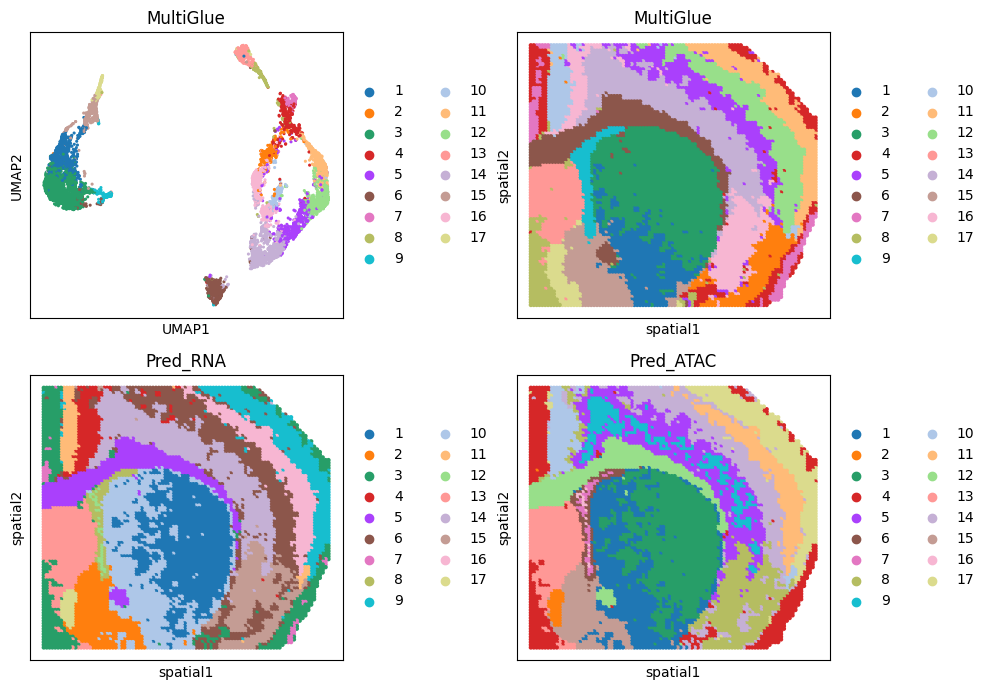

In [19]:
res = 40 #40

fig, ax_list = plt.subplots(2, 2, figsize=(10, 7))
sc.pp.neighbors(adata, use_rep='MultiGlue', n_neighbors=30)
sc.tl.umap(adata, min_dist=0.02)

sc.pl.umap(adata, color='MultiGlue', ax=ax_list[0, 0], title='MultiGlue', s=20, show=False)
sc.pl.embedding(adata, basis='spatial', color='MultiGlue', ax=ax_list[0, 1], title='MultiGlue', s=res, show=False)

sc.pl.embedding(adata, basis='spatial', color='Omics1', ax=ax_list[1, 0], title='Pred_RNA', s=res, show=False)
sc.pl.embedding(adata, basis='spatial', color='Omics2', ax=ax_list[1, 1], title='Pred_ATAC', s=res, show=False)

print(adata)

plt.tight_layout(w_pad=0.3)
plt.show()